# Road speed prediction: GNNs, DeepWalk, neighborhood features, and gradient boosting

**Dataset:** [GraphLand city-roads-L](https://zenodo.org/records/16895532) · **split:** `RH` · **task:** transductive node-level regression.


In this project, we investigate how graph structure can improve road speed prediction. We use the publicly available **GraphLand `city-roads-L` dataset**, where nodes represent road segments, edges represent possible transitions between them, and the target is the average traffic speed.

We focus on the **Random High (RH) split**, using 50% of nodes for training, 25% for validation, and 25% for testing.

Our goal is to compare different approaches to incorporating graph information into regression models:

- **Graph Transformer:** learning neighborhood representations through attention-based message passing.
- **DeepWalk:** learning structural node embeddings through random walks.
- **MLP with graph features:** incorporating manually aggregated neighborhood statistics.
- **Gradient boosting:** comparing LightGBM, XGBoost, and CatBoost on graph-enriched tabular features.
- **Multi-hop feature engineering:** aggregating node features and known target values at different graph distances.

We evaluate the models primarily using \(R^2\), with MAE and RMSE as additional metrics. We also conduct feature ablation experiments to understand which sources of graph information contribute most to predictive performance.



## Results Summary

The table below summarizes the main experimental results on the GraphLand `city-roads-L` dataset (RH split).

| Model | Test R² |
|---|---:|
| Graph Transformer | 0.5756 |
| Graph Transformer + DeepWalk | 0.6271 |
| MLP | 0.5285 |
| MLP + DeepWalk | 0.6091 |
| MLP + DeepWalk + Neighborhood Statistics | 0.6505 |
| MLP + DeepWalk + Neighborhood + Target Statistics | 0.6701 |
| LightGBM + Graph Features | 0.6912 |
| **LightGBM + Multi-hop Features + OOF Target Encoding** | **0.7598** |

The experiments show that graph-derived features substantially improve prediction quality. DeepWalk embeddings are useful when sufficient training labels are available, while manually constructed neighborhood and target statistics provide further gains.

The strongest improvement comes from multi-hop target features, which capture the speeds of labeled road segments at different graph distances. Combined with neighborhood statistics and LightGBM, they achieve the best predictive performance.

In the gradient boosting comparison, XGBoost and LightGBM achieved nearly identical validation performance, while LightGBM was considerably faster to train.

The final model achieves **Test R² = 0.7598, MAE = 1.5664, and RMSE = 2.1164**.

## 0. Install dependencies (Colab)



In [3]:
import sys, subprocess
import torch

subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
                       'torch-geometric>=2.8.0', 'lightgbm', 'scipy',
                       'scikit-learn', 'pandas', 'pyyaml', 'tqdm'])

v = torch.__version__.split('+')[0].split('.')
wheel_torch = f'{v[0]}.{v[1]}.0'
wheel_cuda = 'cpu' if torch.version.cuda is None else 'cu' + torch.version.cuda.replace('.', '')
wheel_url = f'https://data.pyg.org/whl/torch-{wheel_torch}+{wheel_cuda}.html'
print('Torch:', torch.__version__, 'Wheel index:', wheel_url)
subprocess.check_call([
    sys.executable, '-m', 'pip', 'install', '-q', '--force-reinstall',
    '--no-cache-dir', '--no-deps', '--no-index', '-f', wheel_url, 'pyg-lib'
])
print('pyg-lib installed. If PyG was imported before installation, restart the runtime.')

Torch: 2.14.1+cu130 Wheel index: https://data.pyg.org/whl/torch-2.14.0+cu130.html
pyg-lib installed. If PyG was imported before installation, restart the runtime.


In [4]:
import copy
import math
import random
import numpy as np
import pandas as pd
import scipy.sparse as sp
import torch
import torch.nn as nn
import torch.nn.functional as F
import lightgbm as lgb
from sklearn.metrics import r2_score
from sklearn.preprocessing import StandardScaler
from torch.amp import autocast, GradScaler
from tqdm.auto import tqdm
from torch_geometric.datasets import GraphLandDataset
from torch_geometric.nn import MessagePassing, Node2Vec
from torch_geometric.utils import (softmax, to_undirected, remove_self_loops,
                                   scatter, degree, add_self_loops)
import torch_geometric

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
AMP = DEVICE.type == 'cuda'
print('PyTorch:',torch.__version__, 'PyG:',torch_geometric.__version__,
      'pyg-lib available:',torch_geometric.typing.WITH_PYG_LIB, 'Device:',DEVICE)

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


PyTorch: 2.14.1+cu130 PyG: 2.8.1 pyg-lib available: True Device: cuda


## 1. Load GraphLand city-roads-L



In [5]:
dataset = GraphLandDataset(
    root="./data",
    name="city-roads-L",
    split="RH",
    regression_targets_transform=None,
    to_undirected=True,
)


data = dataset[0]
x = data.x.float().cpu()
y = data.y.float().view(-1).cpu()
train_mask, val_mask, test_mask = (data.train_mask.bool().cpu(),
                                   data.val_mask.bool().cpu(),
                                   data.test_mask.bool().cpu())
edge_index = data.edge_index.long().cpu()
edge_index_undirected = to_undirected(edge_index, num_nodes=x.size(0))
edge_index_gnn, _ = add_self_loops(edge_index_undirected, num_nodes=x.size(0))

num_mask = data.x_numerical_mask.bool().cpu()
frac_mask = data.x_fraction_mask.bool().cpu()
cat_mask = data.x_categorical_mask.bool().cpu()
assert int(num_mask.sum()+frac_mask.sum()+cat_mask.sum()) == x.size(1)
assert torch.isfinite(x).all()
assert torch.isfinite(y[train_mask|val_mask|test_mask]).all()
assert not (train_mask & val_mask).any() and not (train_mask & test_mask).any()
print('Nodes:', x.size(0), 'Edges (undirected representation):', edge_index.size(1),
      'Features:', x.size(1))
print('Train / val / test:',*[int(m.sum()) for m in (train_mask,val_mask,test_mask)])
print('Feature types (numerical / fraction / one-hot categorical):',
      int(num_mask.sum()), int(frac_mask.sum()), int(cat_mask.sum()))
print('Target stats (train):',y[train_mask].min().item(),y[train_mask].mean().item(),y[train_mask].max().item())

Extracting data/city-roads-L/raw/city-roads-L.zip
Processing...
Done!


Nodes: 142257 Edges (directed): 463100 Features: 207
Train / val / test: 61733 30866 30867
Feature types (numerical / fraction / one-hot categorical): 6 0 201
Target stats (train): 0.052279599010944366 6.8710618019104 37.55352783203125


## Experiment utilities

Validation is used for checkpoint selection. Test is computed **only for the selected checkpoint**, not each training step. Models are trained from scratch for each experiment.

In [6]:
results = []

def score_predictions(y_true, preds, mask):
    return r2_score(y_true[mask].cpu().numpy(), preds[mask].cpu().numpy())

@torch.no_grad()
def predict_all(model, features, edge_index=None, batch_size=8192):
    model.eval()
    dev = next(model.parameters()).device
    if edge_index is not None:
        with autocast('cuda', enabled=dev.type=='cuda'):
            return model(edge_index.to(dev), features.to(dev)).view(-1).float().cpu()
    outputs = []
    for xx in features.split(batch_size):
        with autocast('cuda', enabled=dev.type=='cuda'):
            outputs.append(model(xx.to(dev)).view(-1).float().cpu())
    return torch.cat(outputs)

def record_result(name, model, features, edge_index=None, best_epoch=None):
    p = predict_all(model, features, edge_index)
    metrics = {f'{s}_r2':score_predictions(y,p,m) for s,m in
               [('train',train_mask),('val',val_mask),('test',test_mask)]}
    results.append({'model':name,**metrics,'best_epoch':best_epoch})
    print(name, metrics, 'best epoch:',best_epoch)
    display(pd.DataFrame(results).round(4))
    return p

## 2. Graph Transformer baseline

We reuse a lightweight multi-head graph attention block with residual connections and an MLP, as in the original exploration. Message passing uses bidirectional edges; the raw road graph remains directed in the dataset.

In [7]:
class FeedForwardModule(nn.Module):
    def __init__(self, dim, dim_multiplier=4, dropout=0.2):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(dim,dim*dim_multiplier),nn.Dropout(dropout),
                                 nn.ReLU(),nn.Linear(dim*dim_multiplier,dim),nn.Dropout(dropout))
    def forward(self,x):
        return self.net(x)

class PyGAttentionModule(MessagePassing):
    def __init__(self,dim,num_heads,dropout):
        super().__init__(aggr='add',node_dim=0)
        assert dim%num_heads==0
        self.num_heads=num_heads
        self.head_dim=dim//num_heads
        self.query=nn.Linear(dim,dim)
        self.key=nn.Linear(dim,dim)
        self.value=nn.Linear(dim,dim)
        self.out_linear=nn.Linear(dim,dim)
        self.dropout=nn.Dropout(dropout)
    def forward(self,graph,x):
        n=x.size(0)
        q=self.query(x).reshape(n,self.num_heads,self.head_dim)
        k=self.key(x).reshape(n,self.num_heads,self.head_dim)
        v=self.value(x).reshape(n,self.num_heads,self.head_dim)
        output=self.propagate(graph,queries=q,keys=k,values=v)
        return self.dropout(self.out_linear(output.flatten(start_dim=1)))
    def message(self,queries_i,keys_j,values_j,index):
        scores=(queries_i*keys_j).sum(-1,keepdim=True)/math.sqrt(self.head_dim)
        attn=softmax(scores,index)
        return attn*values_j

class TransformerModule(nn.Module):
    def __init__(self,dim,num_heads,dim_multiplier,dropout):
        super().__init__()
        self.norm1=nn.LayerNorm(dim)
        self.attn=PyGAttentionModule(dim,num_heads,dropout)
        self.norm2=nn.LayerNorm(dim)
        self.ffn=FeedForwardModule(dim,dim_multiplier,dropout)
    def forward(self,graph,x):
        x=x+self.attn(graph,self.norm1(x))
        return x+self.ffn(self.norm2(x))

class GraphTransformer(nn.Module):
    def __init__(self,input_dim,hidden_dim=128,num_layers=3,num_heads=4,
                 dim_multiplier=4,dropout=0.3):
        super().__init__()
        self.in_linear=nn.Linear(input_dim,hidden_dim)
        self.blocks=nn.ModuleList([TransformerModule(hidden_dim,num_heads,dim_multiplier,dropout)
                                   for _ in range(num_layers)])
        self.last_norm=nn.LayerNorm(hidden_dim)
        self.out_linear=nn.Linear(hidden_dim,1)
    def forward(self,graph,x):
        h=self.in_linear(x)
        for block in self.blocks:
            h=block(graph,h)
        return self.out_linear(self.last_norm(h))

def train_gnn(features, edge_index, epochs=400, lr=1e-3, hidden_dim=128,
              num_layers=3, dropout=0.3, patience=70):
    model=GraphTransformer(features.size(1),hidden_dim,num_layers,dropout=dropout).to(DEVICE)
    opt=torch.optim.Adam(model.parameters(),lr=lr)
    scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(opt,mode='max',factor=0.5,patience=20,min_lr=1e-5)
    scaler=GradScaler('cuda',enabled=AMP)
    xx=features.to(DEVICE); yy=y.to(DEVICE)
    edges=edge_index.to(DEVICE)
    tr=train_mask.to(DEVICE)
    best=-np.inf; state=None; best_epoch=None; stale=0
    bar=tqdm(range(1,epochs+1),desc='Graph Transformer')
    for epoch in bar:
        model.train(); opt.zero_grad(set_to_none=True)
        with autocast('cuda',enabled=AMP):
            pred=model(edges,xx).view(-1)
            loss=F.mse_loss(pred[tr].float(),yy[tr])
        scaler.scale(loss).backward()
        scaler.step(opt); scaler.update()
        model.eval()
        with torch.no_grad(), autocast('cuda',enabled=AMP):
            p=model(edges,xx).view(-1).float().cpu()
        val=score_predictions(y,p,val_mask)
        scheduler.step(val)
        if val>best+1e-5:
            best=val; state=copy.deepcopy(model.state_dict()); best_epoch=epoch; stale=0
        else:
            stale+=1
        if epoch%10==0:bar.set_postfix(val=f'{val:.4f}',best=f'{best:.4f}')
        if stale>=patience:break
    model.load_state_dict(state)
    return model.cpu(),best_epoch

In [8]:
gnn_base, epoch_gnn_base = train_gnn(x, edge_index_gnn)
pred_gnn_base = record_result('Graph Transformer', gnn_base, x, edge_index_gnn,epoch_gnn_base)
del pred_gnn_base
if torch.cuda.is_available():torch.cuda.empty_cache()

Graph Transformer:   0%|          | 0/400 [00:00<?, ?it/s]

Graph Transformer {'train_r2': 0.6278202533721924, 'val_r2': 0.5699886679649353, 'test_r2': 0.5755616426467896} best epoch: 351


,model,train_r2,val_r2,test_r2,best_epoch
0,Graph Transformer,0.6278,0.57,0.5756,351


## 3. DeepWalk structural embeddings + Graph Transformer

`Node2Vec(p=q=1)` produces DeepWalk-style uniform random walks. Its embeddings are trained **without labels** on the complete public transductive graph. Standardize the learned vectors before concatenation.

In [9]:
assert torch_geometric.typing.WITH_PYG_LIB, (
    'Node2Vec needs a pyg-lib build matching the installed torch/CUDA. '
    'Re-run setup and restart the runtime if needed.')

deepwalk=Node2Vec(edge_index_undirected,embedding_dim=64,walk_length=20,
                  context_size=10,walks_per_node=5,num_negative_samples=5,
                  p=1.0,q=1.0,sparse=True).to(DEVICE)
walk_loader=deepwalk.loader(batch_size=256,shuffle=True,num_workers=0)
walk_optimizer=torch.optim.SparseAdam(deepwalk.parameters(),lr=0.01)
for epoch in range(1,11):
    deepwalk.train(); total=0.
    for pos_rw,neg_rw in walk_loader:
        walk_optimizer.zero_grad()
        loss=deepwalk.loss(pos_rw.to(DEVICE),neg_rw.to(DEVICE))
        loss.backward();walk_optimizer.step()
        total+=loss.item()
    print(f'DeepWalk epoch {epoch:02d}: loss {total/len(walk_loader):.4f}')

embeddings=deepwalk.embedding.weight.detach().float().cpu()
embeddings=(embeddings-embeddings.mean(0))/(embeddings.std(0).clamp_min(1e-6))
x_with_embeddings=torch.cat([x,embeddings],dim=1)
print('Features:',x.shape,'=>',x_with_embeddings.shape)
del deepwalk,walk_optimizer
if torch.cuda.is_available():torch.cuda.empty_cache()

DeepWalk epoch 01: loss 2.9961
DeepWalk epoch 02: loss 1.2593
DeepWalk epoch 03: loss 0.9304
DeepWalk epoch 04: loss 0.8306
DeepWalk epoch 05: loss 0.7912
DeepWalk epoch 06: loss 0.7725
DeepWalk epoch 07: loss 0.7627
DeepWalk epoch 08: loss 0.7575
DeepWalk epoch 09: loss 0.7547
DeepWalk epoch 10: loss 0.7533
Features: torch.Size([142257, 207]) => torch.Size([142257, 271])


In [10]:
gnn_deepwalk, epoch_gnn_deepwalk=train_gnn(x_with_embeddings,edge_index_gnn)
record_result('Graph Transformer + DeepWalk',gnn_deepwalk,x_with_embeddings,edge_index_gnn,epoch_gnn_deepwalk)
if torch.cuda.is_available():torch.cuda.empty_cache()

Graph Transformer:   0%|          | 0/400 [00:00<?, ?it/s]

Graph Transformer + DeepWalk {'train_r2': 0.7627243995666504, 'val_r2': 0.6133829355239868, 'test_r2': 0.6271464824676514} best epoch: 394


,model,train_r2,val_r2,test_r2,best_epoch
0,Graph Transformer,0.6278,0.5700,0.5756,351
1,Graph Transformer + DeepWalk,0.7627,0.6134,0.6271,394


## 4. Graph-agnostic MLPs (no graph edges at inference)

The same minibatch MLP is trained twice: first with node features only, then with node features plus DeepWalk embeddings.

In [11]:
def build_mlp(input_dim,hidden_dim=256,hidden_dim_multiplier=4,dropout=0.2):
    wide=hidden_dim*hidden_dim_multiplier
    return nn.Sequential(nn.Linear(input_dim,hidden_dim),nn.ReLU(),nn.Dropout(dropout),
                         nn.Linear(hidden_dim,wide),nn.ReLU(),nn.Dropout(dropout),
                         nn.Linear(wide,hidden_dim),nn.ReLU(),nn.Dropout(dropout),
                         nn.Linear(hidden_dim,1))

def train_mlp(features,epochs=200,lr=1e-3,batch_size=1024,
              hidden_dim=256,dropout=0.2,patience=70):
    model=build_mlp(features.size(1),hidden_dim,dropout=dropout).to(DEVICE)
    opt=torch.optim.Adam(model.parameters(),lr=lr)
    scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(opt,mode='max',factor=.5,patience=20,min_lr=1e-5)
    scaler=GradScaler('cuda',enabled=AMP)
    xx=features.to(DEVICE);yy=y.to(DEVICE)
    train_ids=train_mask.nonzero(as_tuple=True)[0].to(DEVICE)
    best=-np.inf; state=None; best_epoch=None; stale=0
    bar=tqdm(range(1,epochs+1),desc='MLP')
    for epoch in bar:
        model.train()
        ids=train_ids[torch.randperm(train_ids.numel(),device=DEVICE)]
        for batch in ids.split(batch_size):
            opt.zero_grad(set_to_none=True)
            with autocast('cuda',enabled=AMP):
                pred=model(xx[batch]).view(-1)
                loss=F.mse_loss(pred.float(),yy[batch])
            scaler.scale(loss).backward();scaler.step(opt);scaler.update()
        val_pred=predict_all(model,features)
        val=score_predictions(y,val_pred,val_mask)
        scheduler.step(val)
        if val>best+1e-5:
            best=val;best_epoch=epoch;state=copy.deepcopy(model.state_dict());stale=0
        else:stale+=1
        if epoch%10==0:bar.set_postfix(val=f'{val:.4f}',best=f'{best:.4f}')
        if stale>=patience:break
    model.load_state_dict(state)
    return model.cpu(),best_epoch

In [12]:
mlp_plain,epoch_mlp_plain=train_mlp(x)
record_result('MLP',mlp_plain,x,best_epoch=epoch_mlp_plain)
mlp_walk,epoch_mlp_walk=train_mlp(x_with_embeddings)
record_result('MLP + DeepWalk',mlp_walk,x_with_embeddings,best_epoch=epoch_mlp_walk)

MLP:   0%|          | 0/200 [00:00<?, ?it/s]

MLP {'train_r2': 0.6329603791236877, 'val_r2': 0.523972749710083, 'test_r2': 0.5284982919692993} best epoch: 106


,model,train_r2,val_r2,test_r2,best_epoch
0,Graph Transformer,0.6278,0.5700,0.5756,351
1,Graph Transformer + DeepWalk,0.7627,0.6134,0.6271,394
2,MLP,0.6330,0.5240,0.5285,106


MLP:   0%|          | 0/200 [00:00<?, ?it/s]

MLP + DeepWalk {'train_r2': 0.7568718194961548, 'val_r2': 0.6026393175125122, 'test_r2': 0.6090894937515259} best epoch: 27


,model,train_r2,val_r2,test_r2,best_epoch
0,Graph Transformer,0.6278,0.5700,0.5756,351
1,Graph Transformer + DeepWalk,0.7627,0.6134,0.6271,394
2,MLP,0.6330,0.5240,0.5285,106
3,MLP + DeepWalk,0.7569,0.6026,0.6091,27


tensor([ 9.9955, 11.0978, 11.6446,  ..., 13.5867, 15.3493,  7.0115])

## 5. Neighbor attribute aggregation + MLP

For all feature columns, compute the mean of **immediate neighboring nodes**. For continuous numerical columns, also compute min/max; include the normalized node degree. The official loader exposes masks for numerical, fractional and categorical (one-hot) features. We calculate `min/max` for numerical and fraction-valued columns, not one-hot categorical columns. Self loops are removed before aggregation.

In [13]:
edges_no_self,_=remove_self_loops(edge_index_undirected)
src,dst=edges_no_self
n=x.size(0)
neighbor_means=scatter(x[src],dst,dim=0,dim_size=n,reduce='mean')
continuous_mask=num_mask|frac_mask
x_continuous=x[:,continuous_mask]
neighbor_mins=scatter(x_continuous[src],dst,dim=0,dim_size=n,reduce='min')
neighbor_maxs=scatter(x_continuous[src],dst,dim=0,dim_size=n,reduce='max')
node_degree=degree(dst,num_nodes=n,dtype=torch.float32)
normalized_degree=node_degree/node_degree.max().clamp_min(1)
x_aggregated=torch.cat([x_with_embeddings,neighbor_means,
                        neighbor_mins,neighbor_maxs,normalized_degree[:,None]],dim=1)
assert torch.isfinite(x_aggregated).all()
print('Neighbor augmented features:', x_aggregated.shape)

Neighbor augmented features: torch.Size([142257, 491])


In [14]:
mlp_neighbors,epoch_mlp_neighbors=train_mlp(x_aggregated)
record_result('MLP + DeepWalk + neighbors',mlp_neighbors,x_aggregated,best_epoch=epoch_mlp_neighbors)

MLP:   0%|          | 0/200 [00:00<?, ?it/s]

MLP + DeepWalk + neighbors {'train_r2': 0.8681514263153076, 'val_r2': 0.6408064961433411, 'test_r2': 0.6505283117294312} best epoch: 65


,model,train_r2,val_r2,test_r2,best_epoch
0,Graph Transformer,0.6278,0.5700,0.5756,351
1,Graph Transformer + DeepWalk,0.7627,0.6134,0.6271,394
2,MLP,0.6330,0.5240,0.5285,106
3,MLP + DeepWalk,0.7569,0.6026,0.6091,27
4,MLP + DeepWalk + neighbors,0.8682,0.6408,0.6505,65


tensor([ 8.9653, 10.2366, 11.0384,  ..., 11.7968, 13.7800,  8.7906])

## 6. Neighborhood target statistics + MLP

For every node, collect *unique labeled training nodes* reachable within 1–5 hops; exclude the query node itself. Aggregate **only training labels**, never validation/test labels. Impute nodes with no observed training neighbors and add a missingness flag. For train nodes, this is leave-one-node-out but **not full out-of-fold target encoding**: other training labels may occur in each other's neighborhoods. This is a transductive feature and its use should be stated clearly in comparisons.

In [15]:
N=x.size(0)
u,v=edges_no_self.numpy()
A=sp.csr_matrix((np.ones(len(u),dtype=np.bool_), (u,v)),shape=(N,N))
train_nodes=np.flatnonzero(train_mask.numpy())

frontier=A[:,train_nodes].tocsr()
reach=frontier.copy()
for _ in range(4):
    frontier=(A @ frontier).tocsr()
    reach=reach.maximum(frontier).tocsr()

reach=reach.tocoo()
keep=reach.row!=train_nodes[reach.col]
reach=sp.csr_matrix((np.ones(int(keep.sum()),dtype=np.float32),
                     (reach.row[keep],reach.col[keep])),shape=(N,len(train_nodes)))
counts=np.asarray(reach.sum(axis=1)).ravel()
sums=np.asarray(reach @ y.numpy()[train_nodes]).ravel()
valid=counts>0
assert valid.any(), 'No known training targets reachable within 5 hops.'
target_means=np.zeros(N,dtype=np.float32)
target_means[valid]=sums[valid]/counts[valid]
target_means[~valid]=target_means[valid].mean()
missing=(~valid).astype(np.float32)

# Fit the scaler using train nodes only.
scaler=StandardScaler().fit(target_means[train_mask.numpy(),None])
target_means_scaled=scaler.transform(target_means[:,None]).astype(np.float32)
target_features=torch.from_numpy(np.column_stack([target_means_scaled,missing]))
x_part5=torch.cat([x_aggregated,target_features],dim=1)
assert torch.isfinite(x_part5).all()
print('Target aggregate features:',x_part5.shape,
      '| no labeled neighbor fraction:',round(float(missing.mean()),4))
del frontier,reach,A

Target aggregate features: torch.Size([142257, 493]) | no labeled neighbor fraction: 0.0172


In [16]:
mlp_targets,epoch_mlp_targets=train_mlp(x_part5)
record_result('MLP + DeepWalk + neighbors + target means',
              mlp_targets,x_part5,best_epoch=epoch_mlp_targets)

MLP:   0%|          | 0/200 [00:00<?, ?it/s]

MLP + DeepWalk + neighbors + target means {'train_r2': 0.7751907706260681, 'val_r2': 0.662765383720398, 'test_r2': 0.6701221466064453} best epoch: 24


,model,train_r2,val_r2,test_r2,best_epoch
0,Graph Transformer,0.6278,0.5700,0.5756,351
1,Graph Transformer + DeepWalk,0.7627,0.6134,0.6271,394
2,MLP,0.6330,0.5240,0.5285,106
3,MLP + DeepWalk,0.7569,0.6026,0.6091,27
4,MLP + DeepWalk + neighbors,0.8682,0.6408,0.6505,65
5,MLP + DeepWalk + neighbors + target means,0.7752,0.6628,0.6701,24


tensor([ 8.7291, 11.4910,  9.0508,  ...,  9.9871, 12.8620,  7.8560])

## 7. LightGBM

The final model uses **exactly the same engineered features** as the preceding MLP. Early stopping and hyperparameter decisions use validation, not test.

In [17]:
X=x_part5.cpu().numpy()
Y=y.numpy()
tr=train_mask.numpy();va=val_mask.numpy();te=test_mask.numpy()
boost=lgb.LGBMRegressor(n_estimators=2000,learning_rate=0.03,num_leaves=31,
                        max_depth=-1,min_child_samples=20,random_state=SEED,verbosity=-1)
boost.fit(X[tr],Y[tr],eval_set=[(X[va],Y[va])],eval_metric='l2',
          callbacks=[lgb.early_stopping(100),lgb.log_evaluation(100)])
all_preds=torch.from_numpy(boost.predict(X).astype(np.float32))
metrics={f'{name}_r2':score_predictions(y,all_preds,mask)
         for name,mask in [('train',train_mask),('val',val_mask),('test',test_mask)]}
results.append({'model':'LightGBM + all graph features',**metrics,'best_epoch':boost.best_iteration_})
print('Best iteration:',boost.best_iteration_)
display(pd.DataFrame(results).round(4))

Training until validation scores don't improve for 100 rounds
[100]	valid_0's l2: 6.83983
[200]	valid_0's l2: 6.43812
[300]	valid_0's l2: 6.35056
[400]	valid_0's l2: 6.29964
[500]	valid_0's l2: 6.26657
[600]	valid_0's l2: 6.2359
[700]	valid_0's l2: 6.20678
[800]	valid_0's l2: 6.18367
[900]	valid_0's l2: 6.15733
[1000]	valid_0's l2: 6.13733
[1100]	valid_0's l2: 6.11851
[1200]	valid_0's l2: 6.09869
[1300]	valid_0's l2: 6.07526
[1400]	valid_0's l2: 6.05715
[1500]	valid_0's l2: 6.03723
[1600]	valid_0's l2: 6.02115
[1700]	valid_0's l2: 6.00678
[1800]	valid_0's l2: 5.99322
[1900]	valid_0's l2: 5.98163
[2000]	valid_0's l2: 5.9707
Did not meet early stopping. Best iteration is:
[1999]	valid_0's l2: 5.97064


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


Best iteration: 1999


,model,train_r2,val_r2,test_r2,best_epoch
0,Graph Transformer,0.6278,0.5700,0.5756,351
1,Graph Transformer + DeepWalk,0.7627,0.6134,0.6271,394
2,MLP,0.6330,0.5240,0.5285,106
3,MLP + DeepWalk,0.7569,0.6026,0.6091,27
4,MLP + DeepWalk + neighbors,0.8682,0.6408,0.6505,65
5,MLP + DeepWalk + neighbors + target means,0.7752,0.6628,0.6701,24
6,LightGBM + all graph features,0.8231,0.6823,0.6912,1999


## 8. Results and interpretation

The table below is populated **after the experiments finish**. Report test metrics for the models selected on validation. For GitHub, retain the executed cell outputs or export the results as CSV and add a concise comparison in README.

,model,train_r2,val_r2,test_r2,best_epoch
0,Graph Transformer,0.6278,0.5700,0.5756,351
1,Graph Transformer + DeepWalk,0.7627,0.6134,0.6271,394
2,MLP,0.6330,0.5240,0.5285,106
3,MLP + DeepWalk,0.7569,0.6026,0.6091,27
4,MLP + DeepWalk + neighbors,0.8682,0.6408,0.6505,65
5,MLP + DeepWalk + neighbors + target means,0.7752,0.6628,0.6701,24
6,LightGBM + all graph features,0.8231,0.6823,0.6912,1999


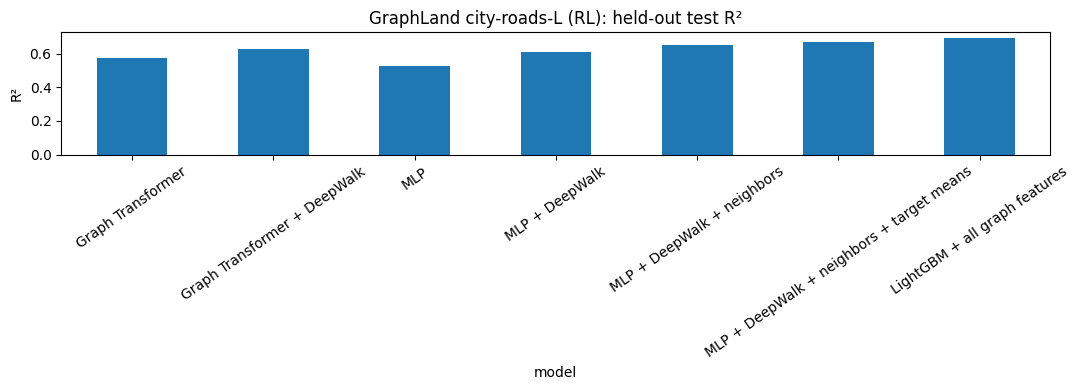

In [18]:
summary=pd.DataFrame(results)
display(summary.round(4))
summary.to_csv('graphland_city_roads_results.csv',index=False)

ax=summary.plot.bar(x='model',y='test_r2',legend=False,figsize=(11,4),rot=35,
                    title='GraphLand city-roads-L (RH): held-out test R²')
ax.set_ylabel('R²')
import matplotlib.pyplot as plt
plt.tight_layout();plt.show()

In [20]:
from itertools import product
from sklearn.metrics import r2_score
import lightgbm as lgb
import pandas as pd
import numpy as np

n_base = x.shape[1]
n_dw = x_with_embeddings.shape[1] - n_base
n_neighbors = x_aggregated.shape[1] - n_base - n_dw

base = x.detach().cpu().numpy()
deepwalk = x_with_embeddings[:, n_base:].detach().cpu().numpy()
neighbors = x_aggregated[:, n_base+n_dw:].detach().cpu().numpy()
targets = x_part5[:, n_base+n_dw+n_neighbors:].detach().cpu().numpy()

Y = y.detach().cpu().numpy()

ablation_results = []
ablation_models = {}

for use_dw, use_neighbors, use_targets in product([False, True], repeat=3):
    parts = [base]

    if use_dw:
        parts.append(deepwalk)
    if use_neighbors:
        parts.append(neighbors)
    if use_targets:
        parts.append(targets)

    X = np.concatenate(parts, axis=1)

    name = (
        f"DW={int(use_dw)}, "
        f"Neighbors={int(use_neighbors)}, "
        f"Targets={int(use_targets)}"
    )

    model = lgb.LGBMRegressor(
        n_estimators=2000,
        learning_rate=0.03,
        num_leaves=31,
        min_child_samples=20,
        random_state=SEED,
        verbosity=-1,
    )

    model.fit(
        X[tr], Y[tr],
        eval_set=[(X[va], Y[va])],
        eval_metric="l2",
        callbacks=[lgb.early_stopping(100, verbose=False)],
    )

    ablation_results.append({
        "model": name,
        "deepwalk": use_dw,
        "neighbors": use_neighbors,
        "targets": use_targets,
        "n_features": X.shape[1],
        "train_r2": r2_score(Y[tr], model.predict(X[tr])),
        "val_r2": r2_score(Y[va], model.predict(X[va])),
        "test_r2": r2_score(Y[te], model.predict(X[te])),
        "best_iteration": model.best_iteration_,
    })

    ablation_models[name] = model

ablation_df = pd.DataFrame(ablation_results)
display(ablation_df.sort_values("val_r2", ascending=False).round(4))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/v

,model,deepwalk,neighbors,targets,n_features,train_r2,val_r2,test_r2,best_iteration
7,"DW=1, Neighbors=1, Targets=1",True,True,True,493,0.8231,0.6823,0.6912,1999
3,"DW=0, Neighbors=1, Targets=1",False,True,True,429,0.7722,0.6787,0.6880,2000
5,"DW=1, Neighbors=0, Targets=1",True,False,True,273,0.7989,0.6518,0.6548,2000
1,"DW=0, Neighbors=0, Targets=1",False,False,True,209,0.7156,0.6451,0.6494,1999
6,"DW=1, Neighbors=1, Targets=0",True,True,False,491,0.7985,0.6361,0.6437,2000
2,"DW=0, Neighbors=1, Targets=0",False,True,False,427,0.7249,0.6206,0.6296,2000
4,"DW=1, Neighbors=0, Targets=0",True,False,False,271,0.7759,0.6020,0.6084,2000
0,"DW=0, Neighbors=0, Targets=0",False,False,False,207,0.6621,0.5883,0.5941,2000


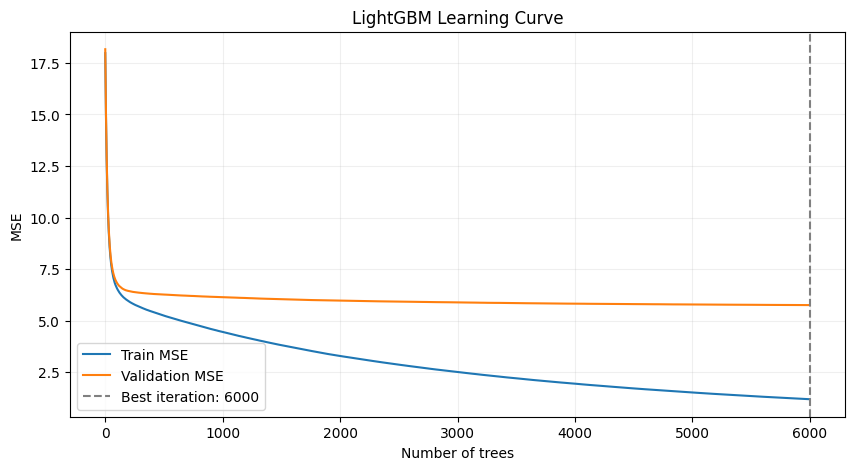

Best iteration: 6000


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


Train R²: 0.936051754198788


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


Validation R²: 0.6937508333741134


In [23]:
import lightgbm as lgb
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

X = x_part5.detach().cpu().numpy()
Y = y.detach().cpu().numpy().ravel()

model = lgb.LGBMRegressor(
    n_estimators=6000,
    learning_rate=0.03,
    num_leaves=31,
    min_child_samples=20,
    random_state=SEED,
    verbosity=-1,
)

model.fit(
    X[tr], Y[tr],
    eval_set=[(X[tr], Y[tr]), (X[va], Y[va])],
    eval_names=["train", "validation"],
    eval_metric="l2",
    callbacks=[lgb.early_stopping(300, verbose=False)],
)

history = model.evals_result_

plt.figure(figsize=(10, 5))
plt.plot(history["train"]["l2"], label="Train MSE")
plt.plot(history["validation"]["l2"], label="Validation MSE")
plt.axvline(
    model.best_iteration_ - 1,
    color="gray",
    linestyle="--",
    label=f"Best iteration: {model.best_iteration_}",
)
plt.xlabel("Number of trees")
plt.ylabel("MSE")
plt.title("LightGBM Learning Curve")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

print("Best iteration:", model.best_iteration_)
print("Train R²:", r2_score(Y[tr], model.predict(X[tr])))
print("Validation R²:", r2_score(Y[va], model.predict(X[va])))

## Gradient boosting comparison

In [26]:
%pip -q install catboost xgboost

In [27]:
import time
import numpy as np
import pandas as pd
import lightgbm as lgb
import xgboost as xgb

from catboost import CatBoostRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

X_boost = x_part5.detach().cpu().numpy().astype(np.float32)
Y_boost = y.detach().cpu().numpy().ravel()

# RH split
X_train, X_val = X_boost[tr], X_boost[va]
y_train, y_val = Y_boost[tr], Y_boost[va]

boosting_models = {
    "LightGBM": lgb.LGBMRegressor(
        n_estimators=6000,
        learning_rate=0.03,
        num_leaves=31,
        min_child_samples=20,
        random_state=SEED,
        verbosity=-1,
        n_jobs=-1,
    ),

    "CatBoost": CatBoostRegressor(
        iterations=6000,
        learning_rate=0.03,
        depth=6,
        loss_function="RMSE",
        eval_metric="RMSE",
        random_seed=SEED,
        verbose=False,
        thread_count=-1,
    ),

    "XGBoost": xgb.XGBRegressor(
        n_estimators=6000,
        learning_rate=0.03,
        max_depth=6,
        min_child_weight=5,
        objective="reg:squarederror",
        tree_method="hist",
        eval_metric="rmse",
        early_stopping_rounds=300,
        random_state=SEED,
        n_jobs=-1,
    ),
}

boosting_results = []
fitted_boosting = {}

for name, model in boosting_models.items():
    print(f"\nTraining {name}...")
    start = time.perf_counter()

    if name == "LightGBM":
        model.fit(
            X_train, y_train,
            eval_set=[(X_val, y_val)],
            eval_metric="l2",
            callbacks=[
                lgb.early_stopping(300, verbose=False)
            ],
        )

        best_iteration = model.best_iteration_

    elif name == "CatBoost":
        model.fit(
            X_train, y_train,
            eval_set=(X_val, y_val),
            early_stopping_rounds=300,
            use_best_model=True,
            verbose=False,
        )

        best_iteration = model.best_iteration_ + 1

    else:
        model.fit(
            X_train, y_train,
            eval_set=[(X_val, y_val)],
            verbose=False,
        )

        best_iteration = model.best_iteration + 1

    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    boosting_results.append({
        "model": name,
        "train_r2": r2_score(y_train, train_pred),
        "val_r2": r2_score(y_val, val_pred),
        "val_mae": mean_absolute_error(y_val, val_pred),
        "val_rmse": np.sqrt(
            mean_squared_error(y_val, val_pred)
        ),
        "best_iteration": best_iteration,
        "time_sec": time.perf_counter() - start,
    })

    fitted_boosting[name] = model

boosting_df = pd.DataFrame(boosting_results)
boosting_df = boosting_df.sort_values(
    "val_r2", ascending=False
)

display(boosting_df.round(4))


Training LightGBM...


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(



Training CatBoost...

Training XGBoost...


,model,train_r2,val_r2,val_mae,val_rmse,best_iteration,time_sec
2,XGBoost,0.9600,0.6940,1.7946,2.3979,5987,640.5839
0,LightGBM,0.9359,0.6938,1.7983,2.3989,5990,184.5051
1,CatBoost,0.8207,0.6894,1.8215,2.4158,5999,297.8771


From here we can see, that the three boosting methods achieve similar validation quality, but LGBM is the fastest one, therefore we're going to use it in next experiments

## Multi-hop neighborhood features

We can aggregate node features over multi-hop neighborhoods rather than considering only immediate neighbors. Specifically, we find nodes at shortest-path distances of exactly 2 and 3 edges and compute the mean of each feature within these neighborhoods. Since 1-hop statistics are already included, this adds 414 new features (207 for each hop), allowing the model to capture information from a broader graph context.

In [28]:
import numpy as np
import scipy.sparse as sp
import torch

from torch_geometric.utils import remove_self_loops

N = x.shape[0]
x_np = x.detach().cpu().numpy().astype(np.float32)

edge_clean, _ = remove_self_loops(edge_index_gnn.cpu())
src, dst = edge_clean.numpy()

A = sp.csr_matrix(
    (np.ones(len(src), dtype=np.float32), (src, dst)),
    shape=(N, N)
)
A = A.maximum(A.T)
A.data[:] = 1


rings = {}

seen = sp.eye(N, dtype=np.float32, format="csr")
frontier = seen

for hop in range(1, 4):
    frontier = (frontier @ A).tocsr()
    frontier.data[:] = 1

    frontier = frontier - frontier.multiply(seen)
    frontier.eliminate_zeros()

    rings[hop] = frontier.copy()

    seen = (seen + frontier).tocsr()
    seen.data[:] = 1

    print(f"Hop {hop}: {frontier.nnz:,} reachable pairs")

hop_feature_parts = []

for hop in (2, 3):
    R = rings[hop]

    counts = np.asarray(R.sum(axis=1)).ravel()
    sums = np.asarray(R @ x_np)

    means = np.divide(
        sums,
        counts[:, None],
        out=np.zeros_like(sums, dtype=np.float32),
        where=counts[:, None] > 0,
    )

    hop_feature_parts.append(means)

hop_features = np.concatenate(hop_feature_parts, axis=1)

print("New neighborhood features:", hop_features.shape)

Hop 1: 463,100 reachable pairs
Hop 2: 754,094 reachable pairs
Hop 3: 971,312 reachable pairs
New neighborhood features: (142257, 414)


## Multi-hop Target Encoding

In addition to aggregating node features, we construct features based on the known target values of nearby labeled nodes.

For each node, we consider neighbors at shortest-path distances of exactly 1, 2, and 3 edges. At each distance, we compute three statistics:

- **Mean target value:** the average speed of labeled neighboring nodes.
- **Labeled neighbor count:** the number of neighbors with known targets, transformed using `log1p`.
- **Missing indicator:** whether no labeled neighbors are available at that distance.

This produces nine additional features per node. When no labeled neighbors are available, the mean target feature is filled with the mean target value of the available training nodes.

### Preventing Target Leakage

Since these features depend on target values, they must be constructed carefully to avoid leaking information from the predicted node.

We use **5-fold out-of-fold (OOF) target encoding** for the training set:

1. Split the training nodes into five folds.
2. For each fold, construct target-based features using labels from the other four folds only.
3. Assign the resulting features to nodes in the held-out fold.
4. Repeat until all training nodes have OOF features.

For validation and test nodes, features are computed using only the full training set's labels. Validation and test targets are never used during feature construction.

This procedure prevents direct target leakage and reduces the risk of the model simply memorizing training labels through graph-based aggregations.

However, the availability of labeled neighbors differs between OOF training features and validation/test features, and random graph splits do not measure generalization to entirely unseen geographical regions.

In [29]:
from sklearn.model_selection import KFold

Y = y.detach().cpu().numpy().ravel()

train_idx = np.flatnonzero(
    train_mask.detach().cpu().numpy()
)
val_idx = np.flatnonzero(
    val_mask.detach().cpu().numpy()
)
test_idx = np.flatnonzero(
    test_mask.detach().cpu().numpy()
)


def make_target_features(source_idx):
    known = np.zeros(N, dtype=np.float32)
    known[source_idx] = 1.0

    known_y = np.zeros(N, dtype=np.float32)
    known_y[source_idx] = Y[source_idx]

    fallback = float(Y[source_idx].mean())
    output = []

    for hop in range(1, 4):
        R = rings[hop]

        counts = np.asarray(R @ known).ravel()
        sums = np.asarray(R @ known_y).ravel()

        means = np.full(N, fallback, dtype=np.float32)
        valid = counts > 0
        means[valid] = sums[valid] / counts[valid]

        output.extend([
            means,
            np.log1p(counts).astype(np.float32),
            (~valid).astype(np.float32),
        ])

    return np.column_stack(output).astype(np.float32)


target_oof = make_target_features(train_idx)

# Train: out-of-fold features.
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)

for fold, (source_pos, heldout_pos) in enumerate(
    kf.split(train_idx), start=1
):
    source_idx = train_idx[source_pos]
    heldout_idx = train_idx[heldout_pos]

    fold_features = make_target_features(source_idx)
    target_oof[heldout_idx] = fold_features[heldout_idx]

    assert np.intersect1d(source_idx, heldout_idx).size == 0

    print(f"OOF fold {fold}/5 complete")

print("Target features:", target_oof.shape)
print("Finite:", np.isfinite(target_oof).all())

OOF fold 1/5 complete
OOF fold 2/5 complete
OOF fold 3/5 complete
OOF fold 4/5 complete
OOF fold 5/5 complete
Target features: (142257, 9)
Finite: True


In [30]:
import lightgbm as lgb
import pandas as pd

from sklearn.metrics import r2_score

base_features = x_aggregated.detach().cpu().numpy().astype(np.float32)

feature_sets = {
    "Existing graph features": base_features,
    "Graph + multi-hop neighborhoods": np.concatenate(
        [base_features, hop_features], axis=1
    ),
    "Graph + OOF target features": np.concatenate(
        [base_features, target_oof], axis=1
    ),
    "All multi-hop features": np.concatenate(
        [base_features, hop_features, target_oof], axis=1
    ),
}

multihop_results = []
multihop_models = {}

for name, X in feature_sets.items():
    print(f"\nTraining: {name}")

    model = lgb.LGBMRegressor(
        n_estimators=6000,
        learning_rate=0.03,
        num_leaves=31,
        min_child_samples=20,
        random_state=SEED,
        verbosity=-1,
        n_jobs=-1,
    )

    model.fit(
        X[train_idx], Y[train_idx],
        eval_set=[(X[val_idx], Y[val_idx])],
        eval_metric="l2",
        callbacks=[
            lgb.early_stopping(300, verbose=False)
        ],
    )

    multihop_results.append({
        "model": name,
        "n_features": X.shape[1],
        "train_r2": r2_score(
            Y[train_idx], model.predict(X[train_idx])
        ),
        "val_r2": r2_score(
            Y[val_idx], model.predict(X[val_idx])
        ),
        "best_iteration": model.best_iteration_,
    })

    multihop_models[name] = model

multihop_df = pd.DataFrame(multihop_results)

display(
    multihop_df.sort_values(
        "val_r2", ascending=False
    ).round(4)
)


Training: Existing graph features


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(



Training: Graph + multi-hop neighborhoods


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(



Training: Graph + OOF target features


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(



Training: All multi-hop features


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


,model,n_features,train_r2,val_r2,best_iteration
3,All multi-hop features,914,0.8809,0.7563,2704
2,Graph + OOF target features,500,0.9240,0.7518,4638
1,Graph + multi-hop neighborhoods,905,0.9381,0.6759,5997
0,Existing graph features,491,0.9353,0.6702,5998


In [31]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

best_name = "All multi-hop features"
best_model = multihop_models[best_name]

X_best = feature_sets[best_name]

y_test = Y[test_idx]
test_pred = best_model.predict(X_best[test_idx])

print(f"Model: {best_name}")
print(f"Best iteration: {best_model.best_iteration_}")
print(f"Test R²:   {r2_score(y_test, test_pred):.6f}")
print(f"Test MAE:  {mean_absolute_error(y_test, test_pred):.4f}")
print(f"Test RMSE: {np.sqrt(mean_squared_error(y_test, test_pred)):.4f}")

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


Model: All multi-hop features
Best iteration: 2704
Test R²:   0.759787
Test MAE:  1.5664
Test RMSE: 2.1164


## Conclusions

The strongest model combines structural embeddings, explicit multi-hop node statistics, and leakage-aware out-of-fold neighborhood target features with LightGBM. On the GraphLand `city-roads-L` RH split, it achieved **test R² = 0.7598**, **MAE = 1.5664**, and **RMSE = 2.1164**.

Target-based neighborhood statistics contributed the largest validation improvement in our experiments. On the original graph-feature matrix, LightGBM, XGBoost, and CatBoost had similar validation performance, while LightGBM trained fastest in our environment.

**Evaluation scope:** these experiments use a transductive random-node split, not a spatial holdout of entire geographical regions. The test split was inspected during exploratory development, so the reported scores should not be interpreted as estimates from a completely untouched final benchmark.
